<a href="https://colab.research.google.com/github/vlasceanuadriana/ML-Seminar-VlasceanuAdriana/blob/main/LP3_Machine_Learning_in_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laborator 3 — Explorarea și preprocesarea datelor

**Curs:** Machine Learning in Python · Laborator asociat Cursului 3 (Preprocesarea datelor)

### Ce vei învăța în acest laborator
- Explorarea unui set de date real (consum de combustibil și emisii CO₂): statistici, distribuții, corelații
- Interpretarea statisticilor descriptive (omogenitate, outlieri, asimetrie, boltire)
- Transformarea logaritmică a unei variabile asimetrice
- Detectarea și tratarea outlierilor (regula IQR)
- Codificarea variabilelor categoriale și scalarea celor numerice
- Gestionarea valorilor lipsă: eliminare, imputare simplă și avansată (set de date Boston Housing)

> 💡 Rulează celulele în ordine, de sus în jos. Celulele marcate **📝 Exercițiu** sunt pentru tine.

## 0. Importul librăriilor

In [1]:
# Librării de bază
import os
import numpy as np
import pandas as pd

# Vizualizare
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesare (scikit-learn)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer, KNNImputer

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')

# Partea 1 — Setul de date FuelConsumption

## 1. Încărcarea datelor

`FuelConsumption.csv` conține informații despre consumul de combustibil al diverselor tipuri de autoturisme și despre emisiile de CO₂ (date din Canada, anul 2023).

Celula de mai jos caută fișierul în același folder cu notebook-ul. Dacă lucrați în **Google Colab**, încărcați fișierul în Drive și completați calea în variabila `COLAB_PATH`.

In [3]:
FUEL_FILE = "FuelConsumption.csv"
COLAB_PATH = "/content/drive/MyDrive/Seminar ML/FuelConsumption.csv"   # modificați dacă folosiți Colab

if not os.path.exists(FUEL_FILE):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        FUEL_FILE = COLAB_PATH
    except ImportError:
        raise FileNotFoundError(
            "Nu găsesc 'FuelConsumption.csv'. Copiați fișierul în același folder cu notebook-ul și rulați din nou."
        )

Fuel_df = pd.read_csv(FUEL_FILE, encoding='latin-1')
Fuel_df.head(10)

Mounted at /content/drive


,Model (year),Make,Model,Vehicle Class,Engine Size (L),Cylinders,Transmission,Fuel type,Fuel Consumption City,Fuel Consumption Hwy,Fuel Consumption Comb,Fuel Consumption City Comb_mpg,CO2 Emissions,CO2 rating,Smog rating
0,2023,Acura,Integra,Full-size,1.5,4,AV7,Z,7.9,6.3,7.2,39,167,6,7
1,2023,Acura,Integra A-SPEC,Full-size,1.5,4,AV7,Z,8.1,6.5,7.4,38,172,6,7
2,2023,Acura,Integra A-SPEC,Full-size,1.5,4,M6,Z,8.9,6.5,7.8,36,181,6,6
3,2023,Acura,MDX SH-AWD,SUV: Small,3.5,6,AS10,Z,12.6,9.4,11.2,25,263,4,5
4,2023,Acura,MDX SH-AWD Type S,SUV: Standard,3.0,6,AS10,Z,13.8,11.2,12.4,23,291,4,5
5,2023,Acura,RDX SH-AWD,SUV: Small,2.0,4,AS10,Z,11.0,8.6,9.9,29,232,5,6
6,2023,Acura,RDX SH-AWD A-SPEC,SUV: Small,2.0,4,AS10,Z,11.3,9.1,10.3,27,242,5,6
7,2023,Acura,TLX SH-AWD,Compact,2.0,4,AS10,Z,11.2,8.0,9.8,29,230,5,7
8,2023,Acura,TLX SH-AWD A-SPEC,Compact,2.0,4,AS10,Z,11.3,8.1,9.8,29,231,5,7
9,2023,Acura,TLX Type S,Compact,3.0,6,AS10,Z,12.3,9.4,11.0,26,256,5,5


## 2. Înțelegerea și explorarea datelor

In [5]:
# dimensiunea tabelului, tipurile de date și numărul de valori nenule
Fuel_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 833 entries, 0 to 832
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Model (year)                    833 non-null    int64  
 1   Make                            833 non-null    object 
 2   Model                           833 non-null    object 
 3   Vehicle Class                   833 non-null    object 
 4   Engine Size (L)                 833 non-null    float64
 5   Cylinders                       833 non-null    int64  
 6   Transmission                    833 non-null    object 
 7   Fuel type                       833 non-null    object 
 8   Fuel Consumption City           833 non-null    float64
 9   Fuel Consumption Hwy            833 non-null    float64
 10  Fuel Consumption Comb           833 non-null    float64
 11  Fuel Consumption City Comb_mpg  833 non-null    int64  
 12  CO2 Emissions                   833 

In [4]:
# statistici descriptive pentru variabilele numerice
Fuel_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Model (year),833.0,2023.000000,0.000000,2023.0,2023.0,2023.0,2023.0,2023.0
Engine Size (L),833.0,3.147899,1.353076,1.2,2.0,3.0,3.6,8.0
Cylinders,833.0,5.627851,1.968695,3.0,4.0,6.0,6.0,16.0
Fuel Consumption City,833.0,12.431453,3.456191,4.4,10.1,12.1,14.6,30.3
Fuel Consumption Hwy,833.0,9.353661,2.302312,4.4,7.7,9.1,10.7,20.9
Fuel Consumption Comb,833.0,11.047179,2.878308,4.4,9.0,10.7,12.9,26.1
Fuel Consumption City Comb_mpg,833.0,27.375750,7.559968,11.0,22.0,26.0,31.0,64.0
CO2 Emissions,833.0,257.471789,64.262847,104.0,211.0,254.0,299.0,608.0
CO2 rating,833.0,4.522209,1.279385,1.0,4.0,5.0,5.0,9.0
Smog rating,833.0,5.236495,1.665693,1.0,5.0,5.0,7.0,8.0


### 🔎 Interpretare

Ce urmărim în tabelul de statistici descriptive:

1. **Min / max față de medie** — o primă idee dacă există outlieri (ex.: `Cylinders` are maximul 16, față de o medie de aproximativ 5,6).
2. **Coeficientul de variație (std / medie)** — dacă este sub ~0,3, datele se pot considera **omogene**; peste această valoare sunt eterogene.
3. **Count** — dacă toate variabilele au același număr de observații, este foarte probabil să nu existe valori lipsă.

In [6]:
# Calculăm automat coeficientul de variație pentru variabilele numerice
num_cols = Fuel_df.select_dtypes(include='number').columns
cv = (Fuel_df[num_cols].std() / Fuel_df[num_cols].mean()).round(2).sort_values(ascending=False)
pd.DataFrame({'Coef. variație': cv, 'Omogenă (CV < 0.3)?': cv < 0.3})

,Coef. variație,Omogenă (CV < 0.3)?
Engine Size (L),0.43,False
Cylinders,0.35,False
Smog rating,0.32,False
CO2 rating,0.28,True
Fuel Consumption City Comb_mpg,0.28,True
Fuel Consumption City,0.28,True
Fuel Consumption Comb,0.26,True
Fuel Consumption Hwy,0.25,True
CO2 Emissions,0.25,True
Model (year),0.00,True


### Selectarea variabilelor de interes

Pentru analiza detaliată păstrăm patru variabile: dimensiunea motorului, numărul de cilindri, consumul combinat și emisiile de CO₂ (variabila pe care am vrea să o prezicem). Folosim `.copy()` pentru a lucra pe o copie independentă — evităm astfel avertismentele de tip *SettingWithCopy*.

In [7]:
cdf = Fuel_df[['Engine Size (L)', 'Cylinders', 'Fuel Consumption Comb', 'CO2 Emissions']].copy()
cdf.head()

,Engine Size (L),Cylinders,Fuel Consumption Comb,CO2 Emissions
0,1.5,4,7.2,167
1,1.5,4,7.4,172
2,1.5,4,7.8,181
3,3.5,6,11.2,263
4,3.0,6,12.4,291


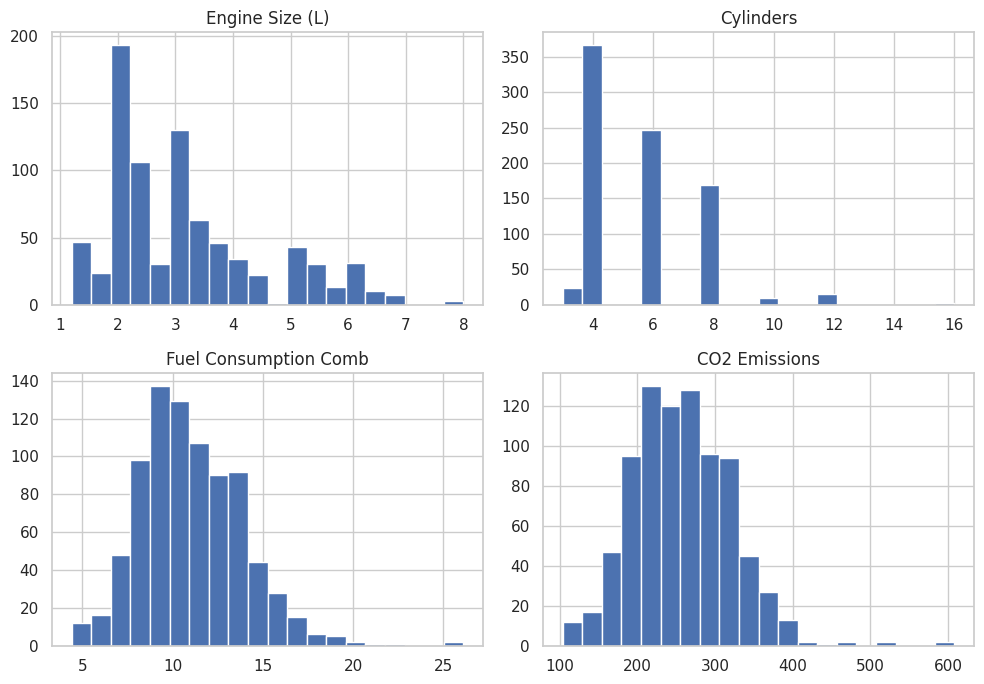

In [8]:
# distribuția fiecărei variabile
cdf.hist(figsize=(10, 7), bins=20)
plt.tight_layout()
plt.show()

Reprezentăm acum fiecare caracteristică în raport cu emisiile de CO₂, pentru a vedea dacă relația este liniară:

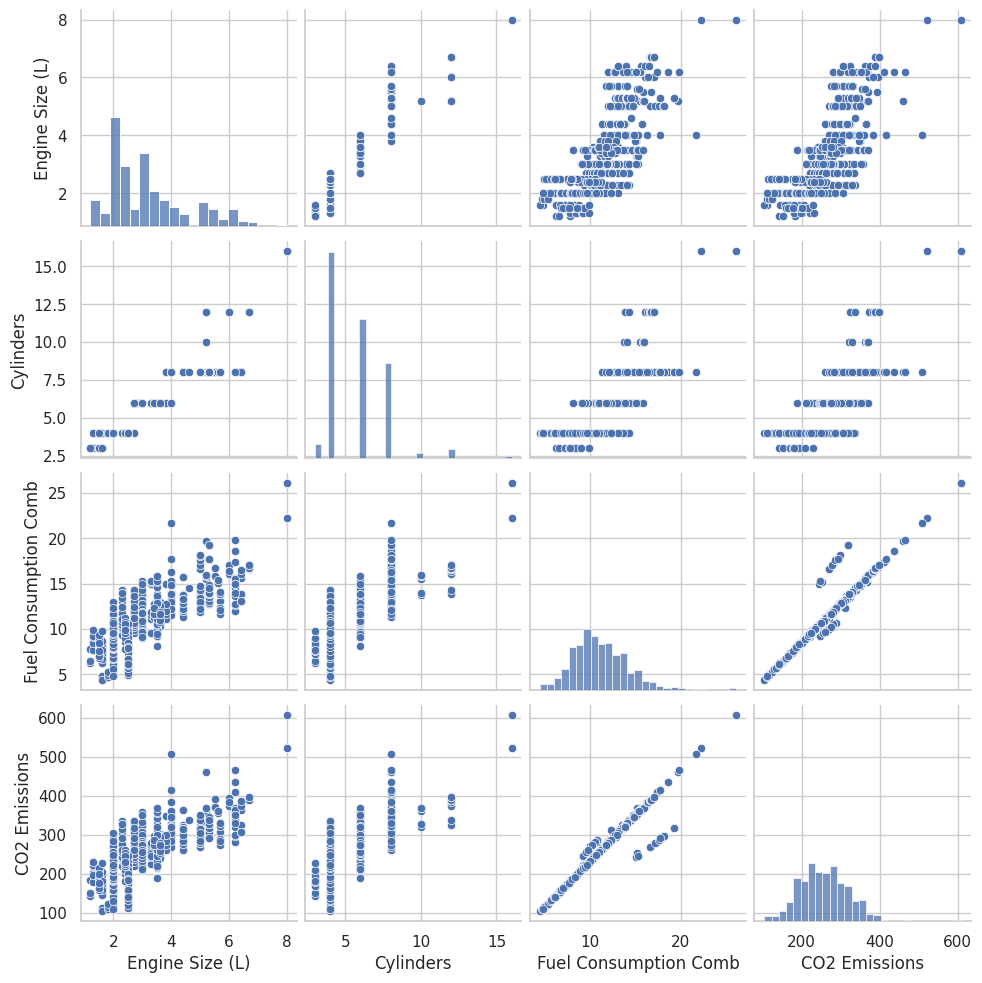

In [9]:
sns.pairplot(cdf);

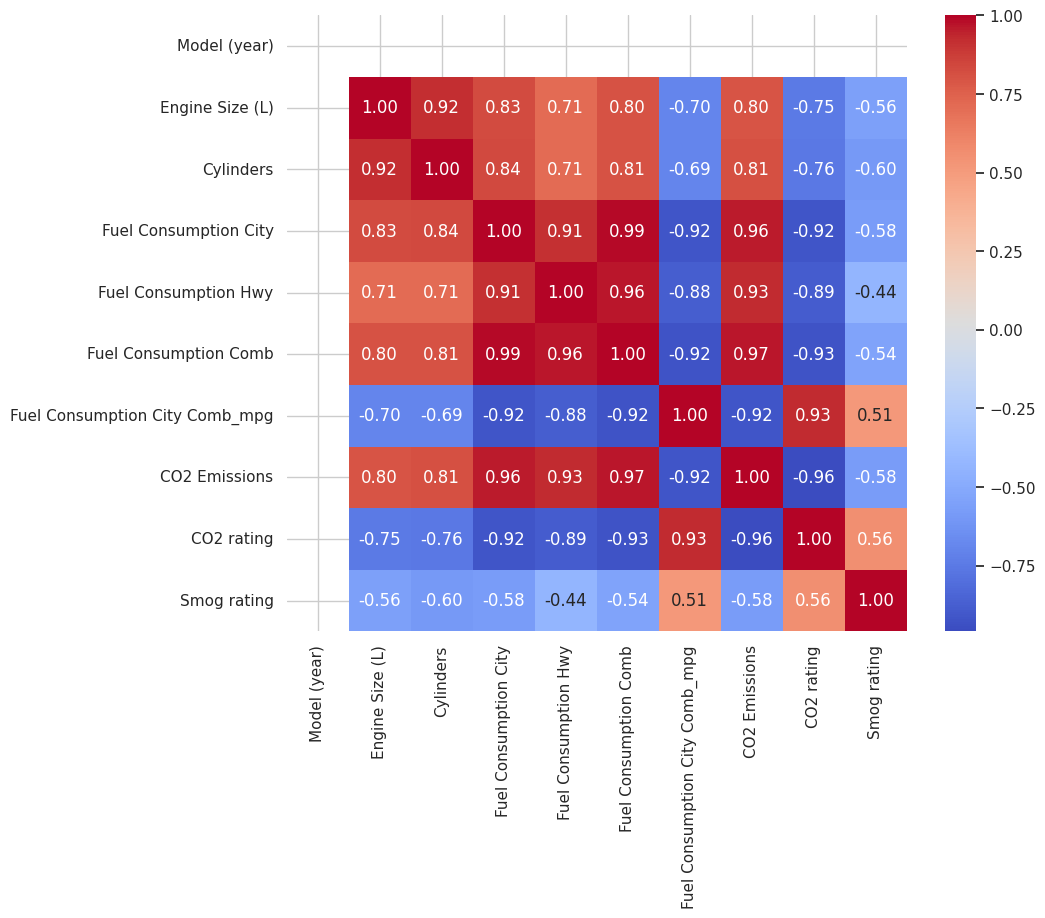

In [10]:
# Heatmap pentru coeficienții de corelație liniară (Pearson)
fig, ax = plt.subplots(figsize=(10, 8))
corrmat = Fuel_df.corr(numeric_only=True)
sns.heatmap(corrmat, annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
plt.show()

### 🔎 Interpretare
Se observă o **corelație puternică și pozitivă** între emisiile de CO₂ și variabilele legate de motor și consum (dimensiunea motorului, numărul de cilindri, consumul de combustibil). Relațiile din `pairplot` sunt aproximativ liniare, ceea ce face acest set de date potrivit pentru un model de **regresie** (Cursul 4).

## 3. Asimetrie (skewness) și boltire (kurtosis)

- **Skewness** — cu cât este mai aproape de 0, cu atât distribuția este mai simetrică (> 0: coadă spre dreapta).
- **Kurtosis** (în exces) — cu cât este mai aproape de 0, cu cât distribuția seamănă mai mult cu cea normală.

In [11]:
def interpreteaza_distributia(serie):
    s, k = serie.skew(), serie.kurt()
    if abs(s) < 0.5:
        verdict = "aproximativ simetrică"
    elif abs(s) < 1:
        verdict = "moderat asimetrică"
    else:
        verdict = "puternic asimetrică"
    print(f"{serie.name}: skewness = {s:.3f}, kurtosis = {k:.3f}  ->  {verdict}")

interpreteaza_distributia(Fuel_df['CO2 Emissions'])

CO2 Emissions: skewness = 0.636, kurtosis = 1.957  ->  moderat asimetrică


## 4. Transformarea logaritmică a variabilei țintă

Logaritmarea reduce asimetria și apropie variabila de o distribuție normală. Comparăm distribuția **înainte** și **după** transformare.

⚠️ Creăm o **coloană nouă** (`log_CO2`) în loc să suprascriem coloana originală — astfel, rularea repetată a celulei nu aplică logaritmul de mai multe ori.

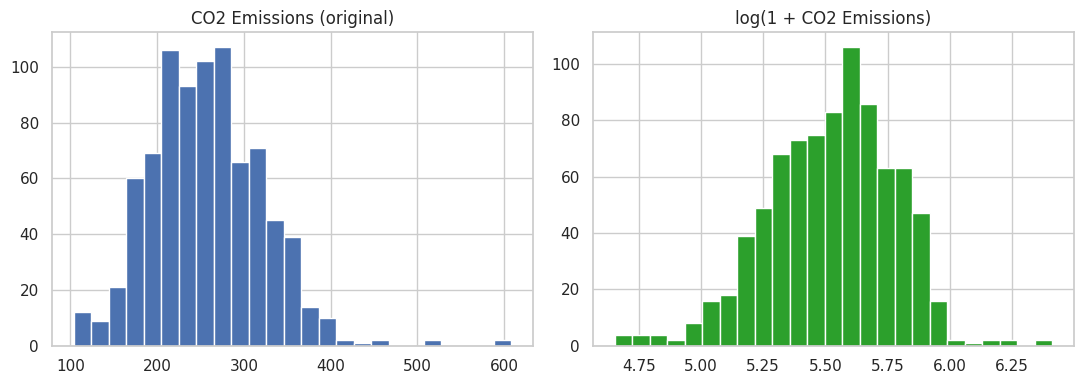

,Skewness,Kurtosis
original,0.636,1.957
logaritmat,-0.340,0.507


In [12]:
Fuel_df['log_CO2'] = np.log1p(Fuel_df['CO2 Emissions'])   # log(1 + x), definit și pentru x = 0

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
Fuel_df['CO2 Emissions'].hist(ax=axes[0], bins=25); axes[0].set_title('CO2 Emissions (original)')
Fuel_df['log_CO2'].hist(ax=axes[1], bins=25, color='tab:green'); axes[1].set_title('log(1 + CO2 Emissions)')
plt.tight_layout(); plt.show()

comparatie = pd.DataFrame({
    'Skewness': [Fuel_df['CO2 Emissions'].skew(), Fuel_df['log_CO2'].skew()],
    'Kurtosis': [Fuel_df['CO2 Emissions'].kurt(), Fuel_df['log_CO2'].kurt()]
}, index=['original', 'logaritmat'])
comparatie.round(3)

### 🔎 Interpretare
Compară cele două rânduri: dacă **valorile absolute** ale skewness-ului și ale kurtosis-ului nu se apropie de 0 după transformare, logaritmarea nu aduce un câștig clar. Decizia de a transforma o variabilă se ia pe baza acestei comparații, nu automat.

## 5. Detectarea și tratarea outlierilor (regula IQR)

O valoare este considerată **outlier** dacă se află în afara intervalului  
`[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]`, unde IQR = Q3 − Q1 (aceeași regulă ca la box plot).

In [13]:
def limite_iqr(serie, k=1.5):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rezumat = []
for col in ['Engine Size (L)', 'Cylinders', 'Fuel Consumption Comb', 'CO2 Emissions']:
    jos, sus = limite_iqr(Fuel_df[col])
    n_out = ((Fuel_df[col] < jos) | (Fuel_df[col] > sus)).sum()
    rezumat.append({'Variabilă': col, 'Limită inferioară': round(jos, 2), 'Limită superioară': round(sus, 2), 'Nr. outlieri': n_out})
pd.DataFrame(rezumat)

,Variabilă,Limită inferioară,Limită superioară,Nr. outlieri
0,Engine Size (L),-0.40,6.00,46
1,Cylinders,1.00,9.00,27
2,Fuel Consumption Comb,3.15,18.75,10
3,CO2 Emissions,79.00,431.00,7


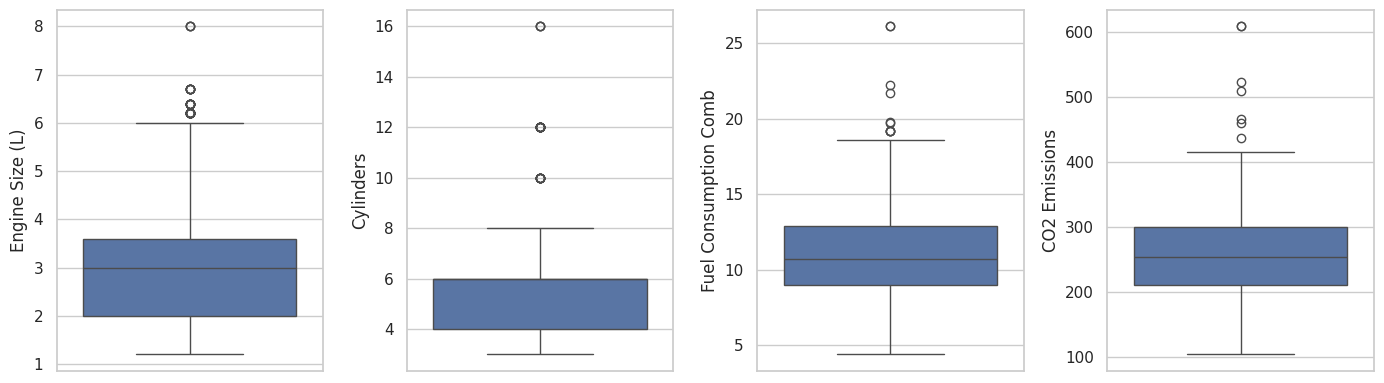

In [14]:
# Box plot — vizualizarea outlierilor
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, ['Engine Size (L)', 'Cylinders', 'Fuel Consumption Comb', 'CO2 Emissions']):
    sns.boxplot(y=Fuel_df[col], ax=ax)
plt.tight_layout(); plt.show()

**Tratare — limitare (capping/winsorizing):** în loc să eliminăm observațiile (și să pierdem informație), înlocuim valorile extreme cu limitele IQR. Salvăm rezultatul într-o coloană nouă.

In [15]:
jos, sus = limite_iqr(Fuel_df['Fuel Consumption Comb'])
Fuel_df['Comb_capped'] = Fuel_df['Fuel Consumption Comb'].clip(lower=jos, upper=sus)

print("Maxim înainte :", Fuel_df['Fuel Consumption Comb'].max())
print("Maxim după    :", Fuel_df['Comb_capped'].max())

Maxim înainte : 26.1
Maxim după    : 18.75


## 6. Codificarea variabilelor categoriale

Modelele de ML lucrează doar cu valori numerice. Variabilele nominale (fără ordine naturală) se transformă prin **One-Hot Encoding** (`pd.get_dummies`).

In [16]:
cate_cols = Fuel_df.select_dtypes(include='object').columns.tolist()
print("Variabile categoriale:", cate_cols)
print("Variabile numerice   :", Fuel_df.select_dtypes(include='number').shape[1])

Variabile categoriale: ['Make', 'Model', 'Vehicle Class', 'Transmission', 'Fuel type']
Variabile numerice   : 12


In [22]:
Fuel_df['Vehicle Class'].value_counts()


,count
Vehicle Class,
SUV: Small,195
SUV: Standard,135
Mid-size,112
Pickup truck: Standard,97
Subcompact,75
Compact,62
Full-size,48
Two-seater,35
Minicompact,22


In [23]:
# Folosim doar două variabile categoriale cu număr mic de categorii
dummies = pd.get_dummies(Fuel_df[['Vehicle Class', 'Fuel type']], drop_first=True)
print("Formă după encoding:", dummies.shape)
dummies.head()

Formă după encoding: (833, 16)


,Vehicle Class_Full-size,Vehicle Class_Mid-size,Vehicle Class_Minicompact,Vehicle Class_Minivan,Vehicle Class_Pickup truck: Small,Vehicle Class_Pickup truck: Standard,Vehicle Class_SUV: Small,Vehicle Class_SUV: Standard,Vehicle Class_Special purpose vehicle,Vehicle Class_Station wagon: Mid-size,Vehicle Class_Station wagon: Small,Vehicle Class_Subcompact,Vehicle Class_Two-seater,Fuel type_E,Fuel type_X,Fuel type_Z
0,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
1,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
2,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
3,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True
4,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True


> ⚠️ `Make` și `Model` au zeci/sute de categorii — One-Hot Encoding ar genera prea multe coloane. Pentru astfel de variabile se grupează categoriile rare sau se folosesc alte codificări.

## 7. Scalarea variabilelor numerice

| Metodă | Formulă | Rezultat |
| --- | --- | --- |
| **Standardizare** (`StandardScaler`) | z = (x − medie) / σ | medie 0, deviație standard 1 |
| **Normalizare** (`MinMaxScaler`) | (x − min) / (max − min) | valori în [0, 1] |

In [24]:
feat = ['Engine Size (L)', 'Cylinders', 'Fuel Consumption Comb']

X_std = pd.DataFrame(StandardScaler().fit_transform(Fuel_df[feat]), columns=feat)
X_mm  = pd.DataFrame(MinMaxScaler().fit_transform(Fuel_df[feat]), columns=feat)

print("Standardizare — medie și deviație standard:")
display(X_std.describe().loc[['mean', 'std']].round(3))
print("Normalizare — minim și maxim:")
display(X_mm.describe().loc[['min', 'max']].round(3))

Standardizare — medie și deviație standard:


,Engine Size (L),Cylinders,Fuel Consumption Comb
mean,0.000,0.000,0.000
std,1.001,1.001,1.001


Normalizare — minim și maxim:


,Engine Size (L),Cylinders,Fuel Consumption Comb
min,0.0,0.0,0.0
max,1.0,1.0,1.0


> 📌 Aici am aplicat scalarea pe întregul set doar pentru demonstrație. Când antrenăm un model (Cursul 4), scaler-ul se potrivește (`fit`) **doar pe datele de antrenament**, apoi se aplică (`transform`) și pe cele de test — altfel apare *data leakage*.

# Partea 2 — Valori lipsă: setul de date Boston Housing

**Despre setul de date.** Datele descriu diferite zone din Boston și au scopul de a prezice prețul median al locuințelor dintr-o zonă (`MEDV`). Observațiile sunt zone/orașe, nu locuințe individuale:

- `CRIM` — rata criminalității pe cap de locuitor
- `ZN` — proporția de teren rezidențial pentru loturi de peste 25.000 sq.ft.
- `INDUS` — proporția de hectare comerciale non-retail pe oraș
- `CHAS` — variabilă dummy Charles River (1 dacă zona delimitează râul; 0 în caz contrar)
- `NOX` — concentrația de oxizi de azot
- `RM` — numărul mediu de camere pe locuință
- `AGE` — proporția unităților construite înainte de 1940
- `DIS` — distanța ponderată până la cinci centre de angajare
- `RAD` — indice de accesibilitate la autostrăzi
- `TAX` — cota de impozit pe proprietate
- `PTRATIO` — raportul elevi/profesori
- `LSTAT` — procentul populației cu statut socio-economic scăzut
- `MEDV` — prețul median al locuințelor (în mii $)

In [25]:
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%203/data/real_estate_data.csv"
LOCAL = "real_estate_data.csv"

try:
    df = pd.read_csv(URL)
    df.to_csv(LOCAL, index=False)          # salvăm o copie locală
except Exception:
    print("Descărcarea a eșuat — folosesc copia locală.")
    df = pd.read_csv(LOCAL)

df_raw = df.copy()      # păstrăm datele originale, pentru comparații ulterioare
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,NaN,36.2


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     486 non-null    float64
 1   ZN       486 non-null    float64
 2   INDUS    486 non-null    float64
 3   CHAS     486 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      486 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  LSTAT    486 non-null    float64
 12  MEDV     506 non-null    float64
dtypes: float64(11), int64(2)
memory usage: 51.5 KB


In [27]:
# Procentul de valori lipsă pe fiecare coloană
(df.isna().mean() * 100).round(2).sort_values(ascending=False)

,0
CRIM,3.95
ZN,3.95
INDUS,3.95
CHAS,3.95
AGE,3.95
LSTAT,3.95
NOX,0.00
DIS,0.00
RM,0.00
RAD,0.00


## 8. Curățarea bazei de date — eliminarea coloanelor cu multe valori lipsă

Definim o funcție care elimină coloanele ce depășesc un **prag procentual** de valori lipsă.

In [28]:
def drop_columns_with_high_nulls(df, threshold_percentage):
    """Elimină coloanele cu mai mult de `threshold_percentage` % valori lipsă."""
    threshold = len(df) * (threshold_percentage / 100)
    dropped_columns = df.columns[df.isnull().sum() > threshold]
    df_cleaned = df.drop(columns=dropped_columns)
    return df_cleaned, dropped_columns

for prag in [10, 3]:
    df_cleaned, dropped = drop_columns_with_high_nulls(df, prag)
    print(f"Prag {prag:>2}%  ->  coloane eliminate: {list(dropped)}")

Prag 10%  ->  coloane eliminate: []
Prag  3%  ->  coloane eliminate: ['CRIM', 'ZN', 'INDUS', 'CHAS', 'AGE', 'LSTAT']


### 🔎 Interpretare
- La un prag de **10%** nu este eliminată nicio coloană (fiecare coloană afectată are ~4% valori lipsă).
- La un prag de **3%** sunt eliminate toate cele 6 coloane afectate — am pierde aproape jumătate din variabile.

Alegerea pragului este o decizie a analistului: aici, **imputarea** este mai potrivită decât eliminarea, deoarece pierderea de informație ar fi mare.

## 9. Imputarea valorilor lipsă cu media

In [29]:
num_data = df.select_dtypes(include=['int64', 'float64']).columns

df_mean = df.copy()
for col in num_data:
    df_mean[col] = df_mean[col].fillna(df_mean[col].mean())

print("Valori lipsă rămase:", df_mean.isna().sum().sum())

Valori lipsă rămase: 0


***ALTE EXERCITII***

**Exercițiul 1.** Analizați baza de date după imputarea cu media: comparați, pentru variabila `LSTAT`, media și deviația standard **înainte** și **după** imputare. Ce observați la deviația standard?

In [30]:

comp = pd.DataFrame({'înainte': df_raw['LSTAT'].describe(), 'după (medie)': df_mean['LSTAT'].describe()})
comp.round(3)


,înainte,după (medie)
count,486.000,506.000
mean,12.715,12.715
std,7.156,7.013
min,1.730,1.730
25%,7.125,7.230
50%,11.430,11.995
75%,16.955,16.570
max,37.970,37.970


**Interpretare:** media rămâne aproape neschimbată, dar deviația standard scade — imputarea cu media „înghesuie” valorile în jurul mediei și subestimează variabilitatea reală a datelor.

**Exercițiul 2.** Imputați valorile lipsă și cu **mediana** (`SimpleImputer(strategy='median')`) și cu **KNN** (`KNNImputer(n_neighbors=5)`). Salvați rezultatele în `df_median` și `df_knn`.

In [31]:
df_median = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(df_raw), columns=df_raw.columns)
df_knn = pd.DataFrame(KNNImputer(n_neighbors=5).fit_transform(df_raw), columns=df_raw.columns)

print("Lipsuri median:", df_median.isna().sum().sum(), "| Lipsuri KNN:", df_knn.isna().sum().sum())


Lipsuri median: 0 | Lipsuri KNN: 0


**Exercițiul 3.** Comparați cele trei metode de imputare pe variabila `LSTAT`: tabel cu media și deviația standard + histogramele suprapuse. Care metodă păstrează cel mai bine forma distribuției originale?

,original (fără NaN),medie,mediană,KNN
mean,12.715,12.715,12.665,12.664
std,7.156,7.013,7.017,7.094


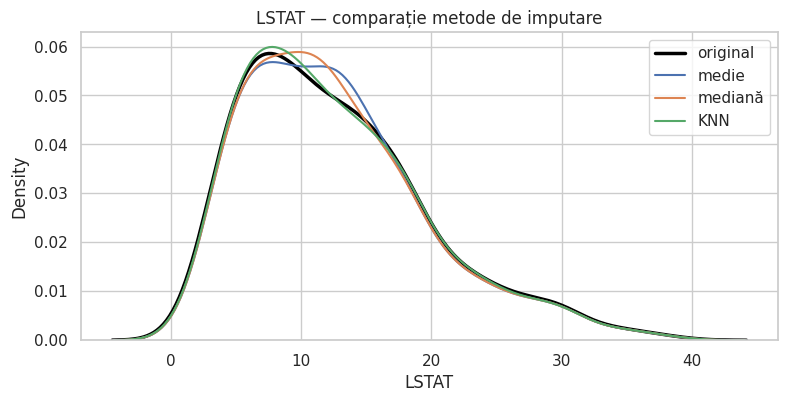

In [32]:
tabel = pd.DataFrame({
    'original (fără NaN)': df_raw['LSTAT'].dropna().agg(['mean', 'std']),
    'medie': df_mean['LSTAT'].agg(['mean', 'std']),
    'mediană': df_median['LSTAT'].agg(['mean', 'std']),
    'KNN': df_knn['LSTAT'].agg(['mean', 'std']),
}).round(3)
display(tabel)

plt.figure(figsize=(9, 4))
sns.kdeplot(df_raw['LSTAT'].dropna(), label='original', linewidth=2.5, color='black')
sns.kdeplot(df_mean['LSTAT'], label='medie')
sns.kdeplot(df_median['LSTAT'], label='mediană')
sns.kdeplot(df_knn['LSTAT'], label='KNN')
plt.legend(); plt.title('LSTAT — comparație metode de imputare'); plt.show()


**Interpretare**:Imputarea cu media/mediana creează un „vârf” artificial în jurul valorii centrale; KNN folosește informația din celelalte variabile și păstrează mai bine forma distribuției.

**Exercițiul 4.** Creați, înainte de imputare, o variabilă binară `LSTAT_missing` (1 dacă valoarea lipsea, 0 altfel). Câte observații au avut valori lipsă la `LSTAT`?

In [33]:
df_flag = df_mean.copy()
df_flag['LSTAT_missing'] = df_raw['LSTAT'].isna().astype(int)
print("Observații cu LSTAT lipsă:", df_flag['LSTAT_missing'].sum())


Observații cu LSTAT lipsă: 20


**Exercițiul 5** Detectați outlierii variabilei `CRIM` cu regula IQR (folosiți `limite_iqr`) și aplicați limitarea (clip). Câți outlieri existau?

In [34]:
jos, sus = limite_iqr(df_mean['CRIM'])
n_out = ((df_mean['CRIM'] < jos) | (df_mean['CRIM'] > sus)).sum()
print(f"Outlieri CRIM: {n_out}")
df_mean['CRIM_capped'] = df_mean['CRIM'].clip(lower=jos, upper=sus)
df_mean[['CRIM', 'CRIM_capped']].describe().round(3)


Outlieri CRIM: 64


,CRIM,CRIM_capped
count,506.000,506.000
mean,3.612,2.228
std,8.546,3.194
min,0.006,0.006
25%,0.083,0.083
50%,0.290,0.290
75%,3.612,3.612
max,88.976,8.905


## Recapitulare

În acest laborator ai exersat:
- ✅ interpretarea statisticilor descriptive (omogenitate, outlieri, asimetrie, boltire)
- ✅ transformarea logaritmică și compararea distribuțiilor înainte/după
- ✅ detectarea și limitarea outlierilor (regula IQR)
- ✅ One-Hot Encoding pentru variabile categoriale și scalarea variabilelor numerice
- ✅ tratarea valorilor lipsă: eliminare pe bază de prag, imputare cu medie / mediană / KNN

➡️ **Următorul laborator** introduce primele modele de **regresie** (Cursul 4), pornind de la datele pregătite aici.